<div style="height: 8px; background: linear-gradient(to right, blue, skyblue, royalblue); border-radius: 4px;"></div>

## Project: Data Quality, Insights & CSV Operations

In [30]:
# load necessary libraries
import numpy as np
import pandas as pd

### Part A | Data Quality & Basic Insights

#### 1. Load and inspect

In [31]:
PATH_FILE = "sales_raw.csv"
df = pd.read_csv(PATH_FILE)

In [32]:

df.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [33]:
# display the shape of the dataframe
df.shape

(21, 6)

In [34]:
# display the column names of the dataframe
df.columns.to_list()

['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

In [35]:
# display the data types of each column in the dataframe
df.dtypes

transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object

In [36]:
# display the summary information of the dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  21 non-null     int64  
 1   sale_date       21 non-null     str    
 2   region          20 non-null     str    
 3   category        21 non-null     str    
 4   quantity        20 non-null     float64
 5   unit_price      20 non-null     str    
dtypes: float64(1), int64(1), str(4)
memory usage: 1.6 KB


In [37]:
# display the number of missing values in each column of the dataframe
df.isna().sum()

transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

In [38]:
# display the number of missing values in each column in descending order of the dataframe
df.isnull().sum().sort_values(ascending=False)

quantity          1
region            1
unit_price        1
transaction_id    0
sale_date         0
category          0
dtype: int64

In [39]:
# display the number of duplicate rows in the dataframe
print(df.duplicated().sum())

1


#### 2. Clean the dataset

In [40]:
# Work on a copy so the original dataframe and CSV remain unchanged.
df_clean = df.copy()


- Trim extra spaces and standardize inconsistent text in region and category

In [41]:
# Standardize text values.
for column in ["region", "category"]:
    df_clean[column] = df_clean[column].astype("string").str.strip().str.title()
    
df_clean["region"] = df_clean["region"].fillna("Unknown")
df_clean["category"] = df_clean["category"].fillna("Unknown")


In [42]:
df_clean.sample(4)

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,Food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
5,1006,10/3/2026,West,Food,NaN,130
8,1009,10/5/2026,West,Food,5.0,90


- Handle missing values, invalid prices and duplicates using sensible rules; explain the choices.

In [43]:
# Parse dates and numeric fields; unparseable values become missing.
df_clean["sale_date"] = pd.to_datetime(
    df_clean["sale_date"], format="%m/%d/%Y", errors="coerce"
)
df_clean["quantity"] = pd.to_numeric(df_clean["quantity"], errors="coerce")
df_clean["unit_price"] = pd.to_numeric(df_clean["unit_price"], errors="coerce")

rows_before = len(df_clean)


In [44]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  21 non-null     int64         
 1   sale_date       20 non-null     datetime64[us]
 2   region          21 non-null     string        
 3   category        21 non-null     string        
 4   quantity        20 non-null     float64       
 5   unit_price      19 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1), string(2)
memory usage: 1.3 KB


- Compare the row count before and after cleaning; preserve the original input CSV.

In [45]:
# Remove exact duplicate rows, then records unsuitable for sales analysis.
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.dropna(subset=["sale_date", "quantity", "unit_price"])
df_clean = df_clean[df_clean["quantity"] >= 0].copy()

print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning:  {len(df_clean)}")
print(f"Rows removed:         {rows_before - len(df_clean)}")

df_clean.head()

Rows before cleaning: 21
Rows after cleaning:  15
Rows removed:         6


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,2026-10-01,North,Food,2.0,120.0
1,1002,2026-10-01,South,Books,1.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0
3,1004,2026-10-02,East,Stationery,4.0,50.0
4,1005,2026-10-03,South,Books,2.0,250.0


#### 3. Calculate and analyze

- Add a revenue column: quantity × unit_price.

In [46]:
# Add a revenue column: quantity × unit_price.
df_clean["revenue"] = df_clean["quantity"] * df_clean["unit_price"]

In [47]:
df_clean.head(2)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2.0,120.0,240.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0


- Use `groupby()` to summarize revenue by region or category.

In [48]:
# Use groupby() to summarize revenue by region or category.
revenue_by_region = df_clean.groupby("region")["revenue"].sum().sort_values(ascending=False)
revenue_by_category = df_clean.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(f"Revenue by region:\n{revenue_by_region}\n{"-"*29}")
print(f"Revenue by category:\n{revenue_by_category}")

Revenue by region:
region
North      11470.0
South       1035.0
East         740.0
West         530.0
Unknown      400.0
Name: revenue, dtype: float64
-----------------------------
Revenue by category:
category
Stationery    10460.0
Food           1945.0
Books          1770.0
Name: revenue, dtype: float64


- Create two labelled charts and write two evidence-based findings.

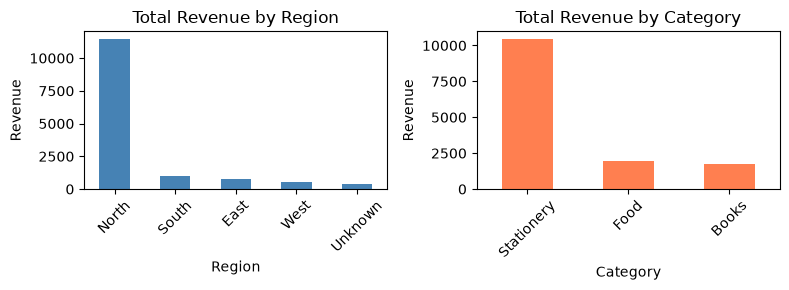

Finding 1: North had the highest regional revenue (11,470).
Finding 2: Stationery had the highest category revenue (10,460).


In [49]:
# load the visualization library for charts and graphs
import matplotlib.pyplot as plt

# create a figure with two subplots for revenue by region and category
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
# plot revenue by region and category as bar charts
revenue_by_region.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Total Revenue by Region", xlabel="Region", ylabel="Revenue")
axes[0].tick_params(axis="x", rotation=45)
# plot revenue by category as a bar chart
revenue_by_category.plot(kind="bar", ax=axes[1], color="coral")
axes[1].set(title="Total Revenue by Category", xlabel="Category", ylabel="Revenue")
axes[1].tick_params(axis="x", rotation=45)
# adjust the layout of the figure to prevent overlapping elements
fig.tight_layout()
plt.show()

# find the top regions and categories by revenue
top_region = revenue_by_region.idxmax()
top_category = revenue_by_category.idxmax()

# display the findings in a formatted manner
print(
    f"Finding 1: {top_region} had the highest regional revenue "
    f"({revenue_by_region[top_region]:,.0f})."
)
print(
    f"Finding 2: {top_category} had the highest category revenue "
    f"({revenue_by_category[top_category]:,.0f})."
)

#### 4. Save the result

- Export a new cleaned_sales.csv using to_csv(..., index=False).

In [50]:
# Export a new cleaned_sales.csv using to_csv(..., index=False).
cleaned_file = "cleaned_sales.csv"
df_clean.to_csv(cleaned_file, index=False)

### Part B | CSV File Handling & Manipulation

> Goal: Edit the CSV created in Part A and save a separate output called sales_updated.csv.

#### 1. Read and add a column

- Load `cleaned_sales.csv` with `pd.read_csv()`.

In [52]:
df_partb = pd.read_csv("cleaned_sales.csv")

- Add tax_amount equal to 5% of revenue and show the first five rows.

In [53]:
# 5% tax_amount add to revenue column
df_partb["tax_amount"] = df_partb["revenue"] * 0.5

# display the first 5 rows
df_partb.head(5)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,120.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0,125.0
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,165.0
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,100.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0,250.0


#### 2. Update and remove

- Use .loc[] to increase the unit_price of Books items by 10%; recalculate revenue and tax_amount.

In [54]:
# Use .loc[] to increase the unit_price of Books items by 10%; recalculate revenue and tax_amount.
df_partb.loc[df_partb["category"] == "Books", "unit_price"] *= 1.10
df_partb["revenue"] = df_partb["quantity"] * df_partb["unit_price"]
df_partb["tax_amount"] = df_partb["revenue"] * 0.5

- Remove one selected row using an existing transaction_id.

In [55]:
df_partb.head(6)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,120.0
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,137.5
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,165.0
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,100.0
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,275.0
5,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,90.0


In [56]:
# delete one row using id
df_partb = df_partb[df_partb["transaction_id"] != 1003]
df_partb.head(6)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,120.0
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,137.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,100.0
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,275.0
5,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,90.0
6,1008,2026-10-04,East,Books,1.0,330.0,330.0,165.0


- Create a temporary review_status column, then remove it with drop(columns=...).

In [58]:
df_partb["quantity"].unique()

array([2., 1., 4., 3., 5.])

In [ ]:
df_partb["review_status"] = np.where(df_partb["quantity"] >= 4.0, "Approved", "Pending")

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,review_status
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,275.0,Pending
8,1012,2026-10-06,North,Books,1.0,352.0,352.0,176.0,Pending
11,1017,2026-10-09,South,Food,3.0,95.0,285.0,142.5,Pending
5,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,90.0,Pending
9,1015,2026-10-08,East,Food,2.0,120.0,240.0,120.0,Pending


In [63]:
df_partb.sample(2)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,review_status
7,1009,2026-10-05,West,Food,5.0,90.0,450.0,225.0,Approved
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,275.0,Pending


In [65]:
# drop the review_status column
df_partb.drop(columns="review_status", inplace=True)
df_partb.tail(5)

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
10,1016,2026-10-08,North,Stationery,1.0,10000.0,10000.0,5000.0
11,1017,2026-10-09,South,Food,3.0,95.0,285.0,142.5
12,1018,2026-10-09,Unknown,Books,2.0,220.0,440.0,220.0
13,1019,2026-10-10,West,Stationery,2.0,40.0,80.0,40.0
14,1020,2026-10-10,North,Food,4.0,100.0,400.0,200.0


#### 3. Save and verify

In [66]:
# Export a new sales_updated.csv. using to_csv(..., index=False).
sales_updated = "sales_updated.csv"
df_clean.to_csv(sales_updated, index=False)

# __THE END__